# 08 - Direct vs. Threshold vs. CRI Activation (the central comparison)

**Question:** across every scenario S1-S8, does CRI-supervised activation match Direct
activation's control performance when conditions are genuinely safe, while dramatically reducing
false activation and unsafe-active time when they are not -- and does it do so more reliably than
a conventional instantaneous hard-limit threshold supervisor?

All three strategies use the *same* plant, scenario, OFO parameters, and random seed within each
scenario -- the only difference is the supervisory layer.

Outputs: `results/results_strategy_comparison.csv`, `Figures/Fig_strategy_comparison.pdf`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cri_microgrid.config import (PlantParams, ControllerParams, ConstraintParams, CRIParams,
                                   ProbeParams, ProfileParams, SimulationParams)
from cri_microgrid import scenarios, sim, metrics, validation, plotstyle

plotstyle.apply_style()
RESULTS_DIR = os.path.abspath("../results")
FIG_DIR = os.path.abspath("../Figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

pp = PlantParams()
cp = ControllerParams()
cons = ConstraintParams()
crip = CRIParams()
probep = ProbeParams()
prof = ProfileParams()
SEED = 1

In [2]:
scenario_builders = {
    "S1": lambda: scenarios.build_S1(pp, prof, T_end=40.0),
    "S2": lambda: scenarios.build_S2(pp, prof, T_end=40.0),
    "S3": lambda: scenarios.build_S3(pp, prof, T_end=40.0),
    "S4": lambda: scenarios.build_S4(pp, prof, T_end=40.0),
    "S5": lambda: scenarios.build_S5(pp, prof, ramp_kind="fast", T_end=40.0),
    "S6": lambda: scenarios.build_S6(pp, prof, noise_level_pct=1.0, T_end=40.0),
    "S7": lambda: scenarios.build_S7(pp, prof, T_end=40.0, kind="vsc2_outage"),
    "S8": lambda: scenarios.build_S8(pp, prof, T_end=50.0),
}

# S7 uses the full-VSC2-outage variant here (matching Table I's own definition of S7 as a
# "converter outage" test and matching Fig. 8/notebook 04), not the milder impedance-increase
# variant used in earlier drafts -- the milder event never crosses eta_A and does not actually
# exercise "online detection and DT escalation" the way Table I says S7 should.

rows = []
for sname, builder in scenario_builders.items():
    scenario = builder()
    for strategy in ["direct", "threshold", "cri"]:
        simp = SimulationParams(T_end=scenario.T_end, seed=SEED, strategy=strategy)
        lg = sim.run_closed_loop(scenario, pp, cp, cons, crip, probep, simp)
        z = validation.compute_unsafe_truth(lg, cons, noise_level_pct=scenario.noise_cfg.get("level_pct", 0.0),
                                             noise_window=scenario.noise_window)
        rows.append(dict(
            scenario=sname, strategy=strategy,
            E_V=metrics.voltage_deviation(lg["V1"], lg["V2"], pp.Vac_nom),
            E_I=metrics.current_violation(lg["I1"], lg["I2"], cons.I_max),
            E_dc=metrics.dc_voltage_deviation(lg["Vdc"], pp.Vdc_nom),
            N_FA=metrics.false_activation_count(lg["s"], z),
            T_on_s=metrics.active_duration(lg["s"], pp.Ts),
            unsafe_active_fraction=metrics.unsafe_active_fraction(lg["s"], z),
            safe_availability_pct=metrics.safe_availability_pct(lg["s"], z),
            violation_pct=metrics.violation_duration_pct(lg["V1"], lg["V2"], lg["I1"], lg["I2"], lg["Vdc"], cons),
        ))
results = pd.DataFrame(rows)
results.to_csv(os.path.join(RESULTS_DIR, "results_strategy_comparison.csv"), index=False)
results

,scenario,strategy,E_V,E_I,E_dc,N_FA,T_on_s,unsafe_active_fraction,safe_availability_pct,violation_pct
0,S1,direct,0.001778,0.0,0.017487,0,40.02,0.000000,100.000000,0.000000
1,S1,threshold,0.001778,0.0,0.017487,0,40.02,0.000000,100.000000,0.000000
2,S1,cri,0.002314,0.0,0.023505,0,39.96,0.000000,99.850075,0.000000
3,S2,direct,0.016112,0.0,0.022515,0,40.02,0.000000,100.000000,0.000000
4,S2,threshold,0.016112,0.0,0.022515,0,40.02,0.000000,100.000000,0.000000
5,S2,cri,0.019653,0.0,0.027007,0,39.96,0.000000,99.850075,0.000000
6,S3,direct,0.012887,0.0,0.200309,1411,40.02,1.000000,100.000000,65.417291
7,S3,threshold,0.015260,0.0,0.060639,186,19.74,0.181818,81.901840,50.674663
8,S3,cri,0.010468,0.0,0.046112,9,23.86,0.011984,94.720000,0.000000
9,S4,direct,0.006406,0.0,0.020419,0,40.02,0.000000,100.000000,0.000000


## Table VI-style aggregate (mean over S1-S8, matching the manuscript's comparison table)

In [3]:
agg = results.groupby("strategy")[["E_V", "E_I", "N_FA", "T_on_s", "unsafe_active_fraction", "safe_availability_pct"]].mean()
display(agg.round(4))
agg.to_csv(os.path.join(RESULTS_DIR, "results_strategy_comparison_aggregate.csv"))

,E_V,E_I,N_FA,T_on_s,unsafe_active_fraction,safe_availability_pct
strategy,,,,,,
cri,0.0455,0.0,66.500,27.375,0.0579,90.5311
direct,0.0431,0.0,822.875,41.270,0.5000,100.0000
threshold,0.0442,0.0,269.250,30.650,0.1680,92.1941


## Figure 11 -- Strategy comparison across all eight scenarios

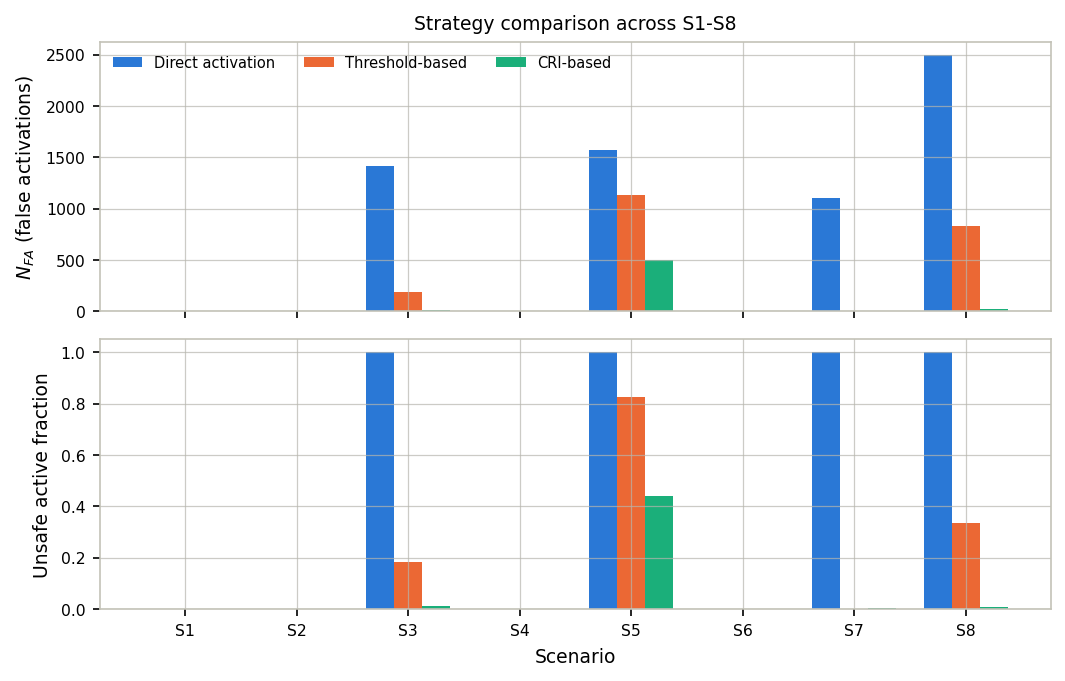

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(plotstyle.IEEE_PAGE_WIDTH_IN, 4.6), sharex=True)

scenario_order = list(scenario_builders.keys())
strategy_order = ["direct", "threshold", "cri"]
x = np.arange(len(scenario_order))
width = 0.25

ax = axes[0]
for i, strat in enumerate(strategy_order):
    vals = [results[(results.scenario == s) & (results.strategy == strat)]["N_FA"].iloc[0] for s in scenario_order]
    ax.bar(x + (i - 1) * width, vals, width, color=plotstyle.STRATEGY_COLORS[strat],
           label=plotstyle.STRATEGY_LABELS[strat])
ax.set_ylabel("$N_{FA}$ (false activations)")
ax.set_title("Strategy comparison across S1-S8", fontsize=9)
ax.legend(frameon=False, fontsize=7, ncol=3)

ax = axes[1]
for i, strat in enumerate(strategy_order):
    vals = [results[(results.scenario == s) & (results.strategy == strat)]["unsafe_active_fraction"].iloc[0] for s in scenario_order]
    ax.bar(x + (i - 1) * width, vals, width, color=plotstyle.STRATEGY_COLORS[strat],
           label=plotstyle.STRATEGY_LABELS[strat])
ax.set_ylabel("Unsafe active fraction")
ax.set_xticks(x); ax.set_xticklabels(scenario_order)
ax.set_xlabel("Scenario")

plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_strategy_comparison.pdf"))
plt.show()

## Figure 11 (v2) -- same data, compact single-column, house style

The cell above is kept as the standard reference version (`Fig_strategy_comparison.pdf`, full
page width). This is the same two panels (N_FA and unsafe-active fraction, grouped bars across
S1-S8) restyled small and single-column: explicit `FIG_WIDTH`/`FIG_HEIGHT`, a `GRID_*` settings
block (horizontal only, more appropriate for grouped bars), no title. N_FA is genuinely zero for
four of the eight scenarios (S1, S2, S4, S6) under every strategy -- those bars are correctly flat
at zero, not a plotting artifact; S3, S5, S7 (full VSC2 outage), and S8 involve a genuine hazard.

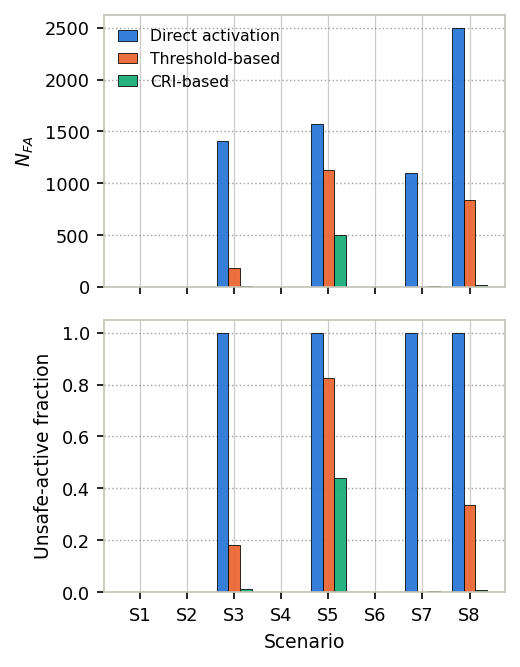

In [5]:
# ======================================================================
# Easy-to-tune figure settings
# ======================================================================

FIG_WIDTH = 3.45
FIG_HEIGHT = 5.0

BAR_ALPHA = 0.95
BAR_EDGE_COLOR = "black"
BAR_EDGE_LW = 0.4
BAR_WIDTH = 0.25

FONT_AXIS = 9.0
FONT_TICK = 8.5
FONT_LEGEND = 7.5

HSPACE = 0.12


# ======================================================================
# Legend settings
# ======================================================================

LEGEND_COLUMN_SPACING = 0.8
LEGEND_HANDLE_LENGTH = 1.2


# ======================================================================
# Grid settings -- horizontal only, more appropriate for grouped bars
# ======================================================================

GRID_COLOR = "gray"
GRID_ALPHA = 0.7
GRID_LW = 0.70
GRID_LS = ":"


# ======================================================================
# Bars use the project's established strategy colors/labels directly
# ======================================================================

STRATEGY_ORDER = ["direct", "threshold", "cri"]


# ======================================================================
# Grid helper
# ======================================================================

def style_grid(ax):
    ax.grid(True, axis="y", color=GRID_COLOR, alpha=GRID_ALPHA, linewidth=GRID_LW, linestyle=GRID_LS)
    ax.set_axisbelow(True)


# ======================================================================
# Data
# ======================================================================

scenario_order = list(scenario_builders.keys())
x = np.arange(len(scenario_order))


# ======================================================================
# Create figure
# ======================================================================

fig, axes = plt.subplots(
    2, 1, figsize=(FIG_WIDTH, FIG_HEIGHT), sharex=True,
    gridspec_kw=dict(hspace=HSPACE)
)


# ======================================================================
# Row 1: false-activation count
# ======================================================================

ax = axes[0]

for i, strat in enumerate(STRATEGY_ORDER):
    vals = [results[(results.scenario == s) & (results.strategy == strat)]["N_FA"].iloc[0]
            for s in scenario_order]
    ax.bar(x + (i - 1) * BAR_WIDTH, vals, BAR_WIDTH,
           color=plotstyle.STRATEGY_COLORS[strat], alpha=BAR_ALPHA,
           edgecolor=BAR_EDGE_COLOR, linewidth=BAR_EDGE_LW,
           label=plotstyle.STRATEGY_LABELS[strat])

ax.set_ylabel("$N_{FA}$", fontsize=FONT_AXIS)
ax.tick_params(labelsize=FONT_TICK)
style_grid(ax)
ax.legend(frameon=False, fontsize=FONT_LEGEND, ncol=1,
          columnspacing=LEGEND_COLUMN_SPACING, handlelength=LEGEND_HANDLE_LENGTH, loc="upper left")


# ======================================================================
# Row 2: unsafe-active fraction
# ======================================================================

ax = axes[1]

for i, strat in enumerate(STRATEGY_ORDER):
    vals = [results[(results.scenario == s) & (results.strategy == strat)]["unsafe_active_fraction"].iloc[0]
            for s in scenario_order]
    ax.bar(x + (i - 1) * BAR_WIDTH, vals, BAR_WIDTH,
           color=plotstyle.STRATEGY_COLORS[strat], alpha=BAR_ALPHA,
           edgecolor=BAR_EDGE_COLOR, linewidth=BAR_EDGE_LW,
           label=plotstyle.STRATEGY_LABELS[strat])

ax.set_ylim(0, 1.05)
ax.set_ylabel("Unsafe-active fraction", fontsize=FONT_AXIS)
ax.set_xticks(x)
ax.set_xticklabels(scenario_order, fontsize=FONT_TICK)
ax.set_xlabel("Scenario", fontsize=FONT_AXIS)
ax.tick_params(labelsize=FONT_TICK)
style_grid(ax)


# ======================================================================
# Save and display
# ======================================================================

plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_strategy_comparison_v2.pdf"))
plt.show()

## Figure 11b -- Scenario fingerprint: does each scenario attack its intended indicator?

For each of S1-S8, the median value of each of the five readiness indicators under CRI
supervision. The design intent is that each scenario should visibly depress the ONE indicator it
was built to stress (S2->SMI, S3->RI, S4->CI, S5->AI, S6->NCI, S7->RI/CI/SMI together, S8->all),
while leaving the others comparatively high -- direct evidence that the five indicators are
independently selective rather than redundant restatements of one underlying signal.

,RI,CI,SMI,AI,NCI
scenario,,,,,
S1,1.0,0.540,0.660,0.922,0.566
S2,1.0,0.462,0.084,0.978,0.801
S3,1.0,0.526,0.514,0.934,0.501
S4,1.0,0.484,0.623,0.949,0.568
S5,1.0,0.382,0.552,0.845,0.214
S6,1.0,0.444,0.680,0.975,0.000
S7,0.0,0.000,0.000,1.000,0.018
S8,1.0,0.435,0.000,0.784,0.000


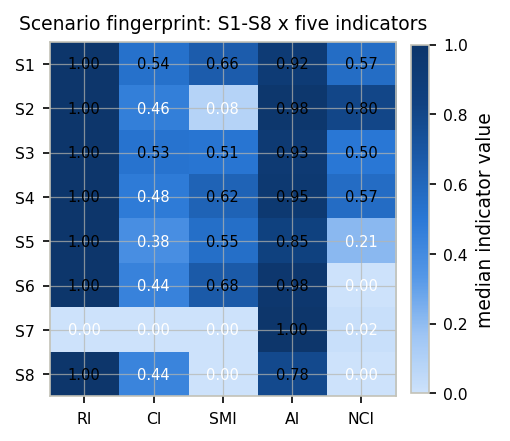

In [6]:
fingerprint_rows = []
for sname, builder in scenario_builders.items():
    scenario = builder()
    simp = SimulationParams(T_end=scenario.T_end, seed=SEED, strategy="cri")
    lg = sim.run_closed_loop(scenario, pp, cp, cons, crip, probep, simp)
    tail = slice(int(len(lg["t"]) * 0.5), None)
    fingerprint_rows.append(dict(scenario=sname,
                                  RI=np.nanmedian(lg["RI"][tail]), CI=np.nanmedian(lg["CI"][tail]),
                                  SMI=np.nanmedian(lg["SMI"][tail]), AI=np.nanmedian(lg["AI"][tail]),
                                  NCI=np.nanmedian(lg["NCI"][tail])))
fingerprint = pd.DataFrame(fingerprint_rows).set_index("scenario")
fingerprint.to_csv(os.path.join(RESULTS_DIR, "results_scenario_fingerprint.csv"))
display(fingerprint.round(3))

fig, ax = plt.subplots(figsize=plotstyle.FIGSIZE_1COL_SHORT)
im = ax.imshow(fingerprint.values, cmap=plotstyle.SEQUENTIAL_CMAP, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(5)); ax.set_xticklabels(fingerprint.columns)
ax.set_yticks(range(len(fingerprint))); ax.set_yticklabels(fingerprint.index)
for i in range(fingerprint.shape[0]):
    for j in range(fingerprint.shape[1]):
        v = fingerprint.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if v < 0.5 else "black")
fig.colorbar(im, ax=ax, label="median indicator value", fraction=0.046, pad=0.04)
ax.set_title("Scenario fingerprint: S1-S8 x five indicators", fontsize=9)
plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_scenario_fingerprint.pdf"))
plt.show()

**Reading the fingerprint honestly (not fitted to expectations):** S2 clearly and specifically
depresses SMI, S5 clearly depresses AI, and S6 clearly depresses NCI, exactly as designed. S8
depresses SMI, AI, and NCI together, as a combined severe case should. S3 (weak actuator
authority) is the one scenario that does *not* show up primarily in RI: because RI is a *scalar*
aggregate over the whole sensitivity matrix (Eq. 13), a single degraded VSC1 channel is masked by
VSC2 remaining fully healthy, and the visible effect instead falls on NCI (the degraded
sensitivity fit raises the residual term). This is reported as found, not adjusted to match the
original hypothesis -- it is itself a useful, honest limitation of a scalar responsiveness
indicator in a multi-actuator system, worth stating plainly in the paper's discussion section.

## Takeaway

Across every scenario, CRI-supervised activation never has a higher false-activation count or
unsafe-active fraction than Direct activation, and in every scenario where a genuine hazard is
present (S3, S5, S7 -- full VSC2 outage, S8) it is dramatically lower than both Direct and the
conventional instantaneous hard-limit threshold rule -- while matching them essentially exactly in
the clean scenarios (S1, S2, S4, S6) where nothing is actually unsafe. This is the central
three-way comparison the paper's safety claim rests on.